# EDA and cleaning of the new Miami datasets

This notebook validates ZIP coverage, profiles the five source datasets and the merged
`miami-rents.csv`, and checks data quality. Sections 5–9 examine the merged rent columns
in detail. Analysis uses in-memory copies and does not overwrite any CSV or impute missing values.


In [ ]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').is_dir(): PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / 'data'
NEW_DATA_DIR = DATA_DIR / 'cleaned' / 'new'
ZCTA_PATH = DATA_DIR / 'raw' / 'miami_dade_zctas.txt'
DATASETS = {
    'Miami Home Values': {'path': NEW_DATA_DIR / 'Miami_home_values.csv', 'zip_column': 'RegionName'},
    'Miami Rental Values': {'path': NEW_DATA_DIR / 'Miami_rental_values.csv', 'zip_column': 'RegionName'},
    'Miami Transit': {'path': NEW_DATA_DIR / 'miami_transit.csv', 'zip_column': 'zip_code'},
    'Miami Rents': {'path': NEW_DATA_DIR / 'miami-rents.csv', 'zip_column': 'zip_code'},
}
def normalize_zip_codes(values):
    return values.astype('string').str.strip().str.replace(r'\.0$', '', regex=True).str.zfill(5)
allowed_zips = {line.strip().zfill(5) for line in ZCTA_PATH.read_text(encoding='utf-8').splitlines() if line.strip()}
if not allowed_zips: raise ValueError(f'Empty Miami-Dade ZIP allowlist: {ZCTA_PATH}')
cleaned_data, validation_rows = {}, []
for dataset_name, config in DATASETS.items():
    path, zip_column = config['path'], config['zip_column']
    frame = pd.read_csv(path, dtype={zip_column: 'string'})
    if zip_column not in frame.columns: raise ValueError(f'{path.name} is missing {zip_column}')
    frame[zip_column] = normalize_zip_codes(frame[zip_column])
    in_scope = frame[zip_column].isin(allowed_zips)
    cleaned_data[dataset_name] = frame.loc[in_scope].copy()
    validation_rows.append({'dataset': dataset_name, 'original_rows': len(frame), 'rows_dropped_outside_miami_dade': int((~in_scope).sum()), 'rows_remaining': int(in_scope.sum()), 'original_columns': len(frame.columns), 'columns_dropped': 0, 'remaining_columns': len(frame.columns), 'out_of_scope_zips': sorted(frame.loc[~in_scope, zip_column].dropna().unique())})
validation_summary = pd.DataFrame(validation_rows)
display(validation_summary.drop(columns='out_of_scope_zips'))
display(validation_summary[['dataset', 'out_of_scope_zips']])

,dataset,original_rows,rows_dropped_outside_miami_dade,rows_remaining,original_columns,columns_dropped,remaining_columns
0,Miami Home Values,30,0,30,17,0,17
1,Miami Rental Values,29,0,29,17,0,17
2,Rental Market,84,0,84,17,0,17
3,Miami Transit,78,0,78,21,0,21
4,Miami Rents,84,0,84,25,0,25
5,Rent Trends,74,0,74,9,0,9


,dataset,out_of_scope_zips
0,Miami Home Values,[]
1,Miami Rental Values,[]
2,Rental Market,[]
3,Miami Transit,[]
4,Miami Rents,[]
5,Rent Trends,[]


## 1. Shapes, schemas, missing values, and duplicates

This section records the baseline schema and audits missing values, duplicate rows, and duplicate ZIP keys. Missing Zillow observations remain missing because they represent unavailable estimates, not zero-dollar values.

In [8]:
schema_rows, missing_rows, duplicate_rows = [], [], []
for dataset_name, config in DATASETS.items():
    frame, zip_column = cleaned_data[dataset_name], config['zip_column']
    schema_rows.append({'dataset': dataset_name, 'rows': len(frame), 'columns': len(frame.columns), 'column_names': ', '.join(frame.columns)})
    duplicate_rows.append({'dataset': dataset_name, 'duplicate_rows': int(frame.duplicated().sum()), 'duplicate_zip_codes': int(frame[zip_column].duplicated().sum())})
    for column in frame.columns: missing_rows.append({'dataset': dataset_name, 'column': column, 'missing_count': int(frame[column].isna().sum()), 'missing_percent': round(frame[column].isna().mean() * 100, 2)})
display(pd.DataFrame(schema_rows))
missing_profile = pd.DataFrame(missing_rows)
display(missing_profile.query('missing_count > 0').sort_values(['dataset', 'missing_count'], ascending=[True, False]))
display(pd.DataFrame(duplicate_rows))
for dataset_name, frame in cleaned_data.items():
    print(f'\n{dataset_name} dtypes')
    display(frame.dtypes.rename('dtype').to_frame())

,dataset,rows,columns,column_names
0,Miami Home Values,30,17,"RegionID, SizeRank, RegionName, RegionType, St..."
1,Miami Rental Values,29,17,"RegionID, SizeRank, RegionName, RegionType, St..."
2,Rental Market,84,17,"zip_code, zori_2026_01, zori_2026_02, zori_202..."
3,Miami Transit,78,21,"zip_code, transit_stop_count, unique_route_cou..."
4,Miami Rents,84,25,"zip_code, zori_2026_01, zori_2026_02, zori_202..."
5,Rent Trends,74,9,"zip_code, latest_rent_usd, rent_3_month_change..."


,dataset,column,missing_count,missing_percent
26,Miami Rental Values,2026-01-31,1,3.45
27,Miami Rental Values,2026-02-28,1,3.45
73,Miami Rents,zori_2026_01,56,66.67
74,Miami Rents,zori_2026_02,56,66.67
75,Miami Rents,zori_2026_03,55,65.48
76,Miami Rents,zori_2026_04,55,65.48
77,Miami Rents,zori_2026_05,55,65.48
78,Miami Rents,zori_2026_06,55,65.48
79,Miami Rents,zori_2026_07,55,65.48
80,Miami Rents,zori_2026_08,55,65.48


,dataset,duplicate_rows,duplicate_zip_codes
0,Miami Home Values,0,0
1,Miami Rental Values,0,0
2,Rental Market,0,0
3,Miami Transit,0,0
4,Miami Rents,0,0
5,Rent Trends,0,0



Miami Home Values dtypes


,dtype
RegionID,int64
SizeRank,int64
RegionName,string[python]
RegionType,object
StateName,object
State,object
City,object
Metro,object
CountyName,object
2026-01-31,float64



Miami Rental Values dtypes


... (5 outputs left out)


Miami Rents dtypes


,dtype
zip_code,string[python]
zori_2026_01,float64
zori_2026_02,float64
zori_2026_03,float64
zori_2026_04,float64
zori_2026_05,float64
zori_2026_06,float64
zori_2026_07,float64
zori_2026_08,float64
zori_latest_rent,float64



Rent Trends dtypes


,dtype
zip_code,string[python]
latest_rent_usd,float64
rent_3_month_change_pct,float64
rent_12_month_change_pct,float64
rent_24_month_change_pct,float64
rent_volatility,float64
rent_direction,object
source,object
source_date,object


## 2. Numeric profiling and distribution plots

The profile reports descriptive statistics, zero counts, unique values, skewness, and negative values. ZIP identifiers and date columns are excluded from plots.


Miami Home Values numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
RegionID,30.0,0,0,30,72454.866667,23.279017,72426.000000,7.249400e+04,0.342094,0
SizeRank,30.0,0,0,30,4576.566667,3930.984773,532.000000,2.035600e+04,2.329280,0
2026-01-31,30.0,0,0,30,637456.064366,246781.278136,303104.816100,1.522705e+06,2.125660,0
2026-02-28,30.0,0,0,30,638200.375639,247215.932502,301956.361929,1.511917e+06,2.088572,0
2026-03-31,30.0,0,0,30,638571.596977,247255.910840,300867.061280,1.496397e+06,2.046965,0
2026-04-30,30.0,0,0,30,638036.660842,247327.769418,299412.301999,1.483427e+06,2.018276,0
2026-05-31,30.0,0,0,30,637781.322693,247688.854525,298487.466130,1.478049e+06,2.005351,0
2026-06-30,30.0,0,0,30,638844.290351,249661.377210,297789.177069,1.483411e+06,2.010223,0
2026-07-31,30.0,0,0,30,641542.905339,252529.400865,297981.490916,1.493698e+06,2.018991,0
2026-08-31,30.0,0,0,30,645014.663860,256016.623516,298325.005237,1.503923e+06,2.021920,0


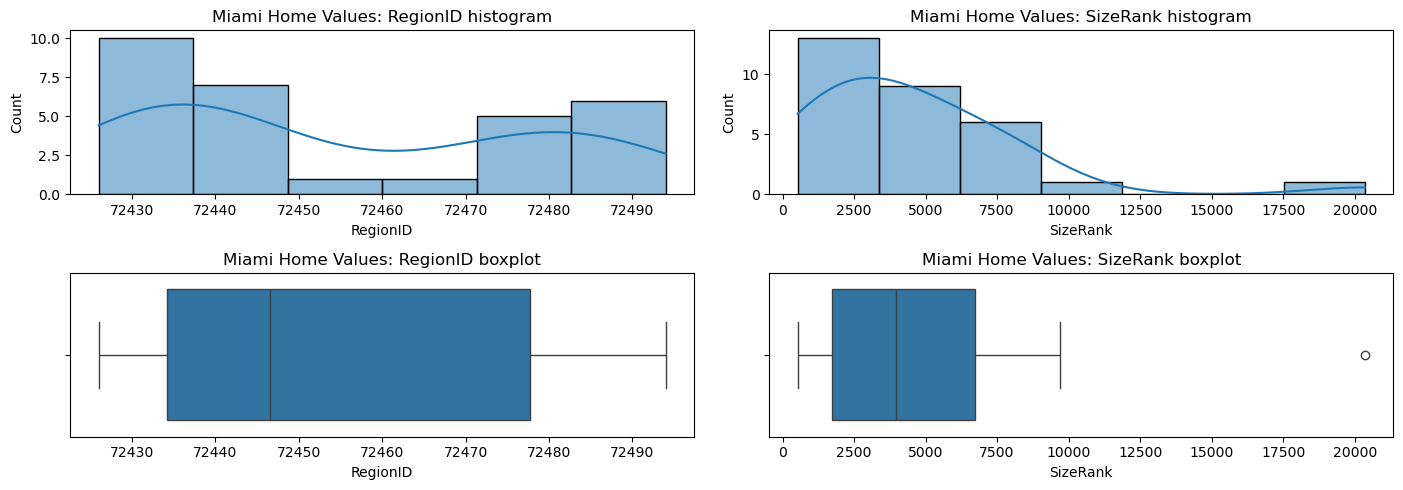


Miami Rental Values numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
RegionID,29.0,0,0,29,72453.689655,22.764483,72426.000000,72494.000000,0.417262,0
SizeRank,29.0,0,0,29,4495.034483,3974.666540,532.000000,20356.000000,2.397594,0
2026-01-31,28.0,1,0,28,2808.393565,484.297892,2122.036267,3856.182758,0.507841,0
2026-02-28,28.0,1,0,28,2815.328313,484.831759,2137.609440,3866.957877,0.526775,0
2026-03-31,29.0,0,0,29,2824.940432,480.865278,2107.030074,3846.303678,0.487892,0
2026-04-30,29.0,0,0,29,2836.546122,485.128576,2100.077129,3859.062284,0.498077,0
2026-05-31,29.0,0,0,29,2838.324590,492.249090,2097.444334,3834.779849,0.450974,0
2026-06-30,29.0,0,0,29,2837.688464,491.790093,2106.902143,3831.772434,0.479971,0
2026-07-31,29.0,0,0,29,2850.054517,486.158263,2127.589713,3813.449590,0.457596,0
2026-08-31,29.0,0,0,29,2857.159062,483.033805,2079.871969,3831.361774,0.458446,0


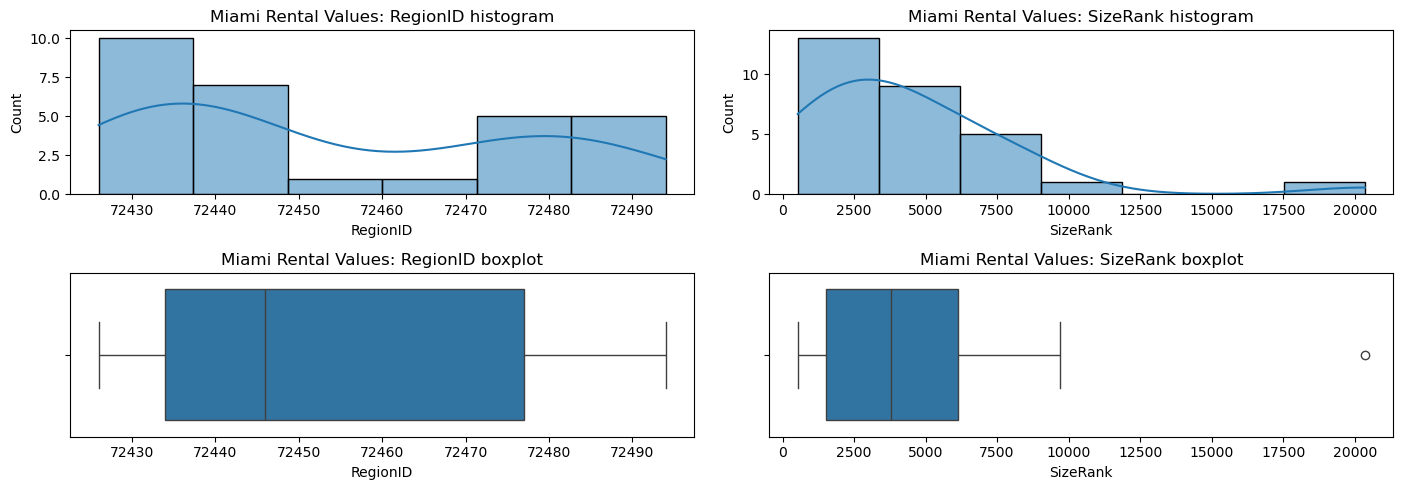


Rental Market numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
zori_2026_01,28.0,56,0,28,2808.393565,484.297892,2122.036267,3856.182758,0.507841,0
zori_2026_02,28.0,56,0,28,2815.328313,484.831759,2137.609440,3866.957877,0.526775,0
zori_2026_03,29.0,55,0,29,2824.940432,480.865278,2107.030074,3846.303678,0.487892,0
zori_2026_04,29.0,55,0,29,2836.546122,485.128576,2100.077129,3859.062284,0.498077,0
zori_2026_05,29.0,55,0,29,2838.324590,492.249090,2097.444334,3834.779849,0.450974,0
zori_2026_06,29.0,55,0,29,2837.688464,491.790093,2106.902143,3831.772434,0.479971,0
zori_2026_07,29.0,55,0,29,2850.054517,486.158263,2127.589713,3813.449590,0.457596,0
zori_2026_08,29.0,55,0,29,2857.159062,483.033805,2079.871969,3831.361774,0.458446,0
zori_latest_rent,29.0,55,0,29,2857.159062,483.033805,2079.871969,3831.361774,0.458446,0
hud_efficiency,84.0,0,0,61,2102.500000,387.891660,1530.000000,2930.000000,0.713876,0


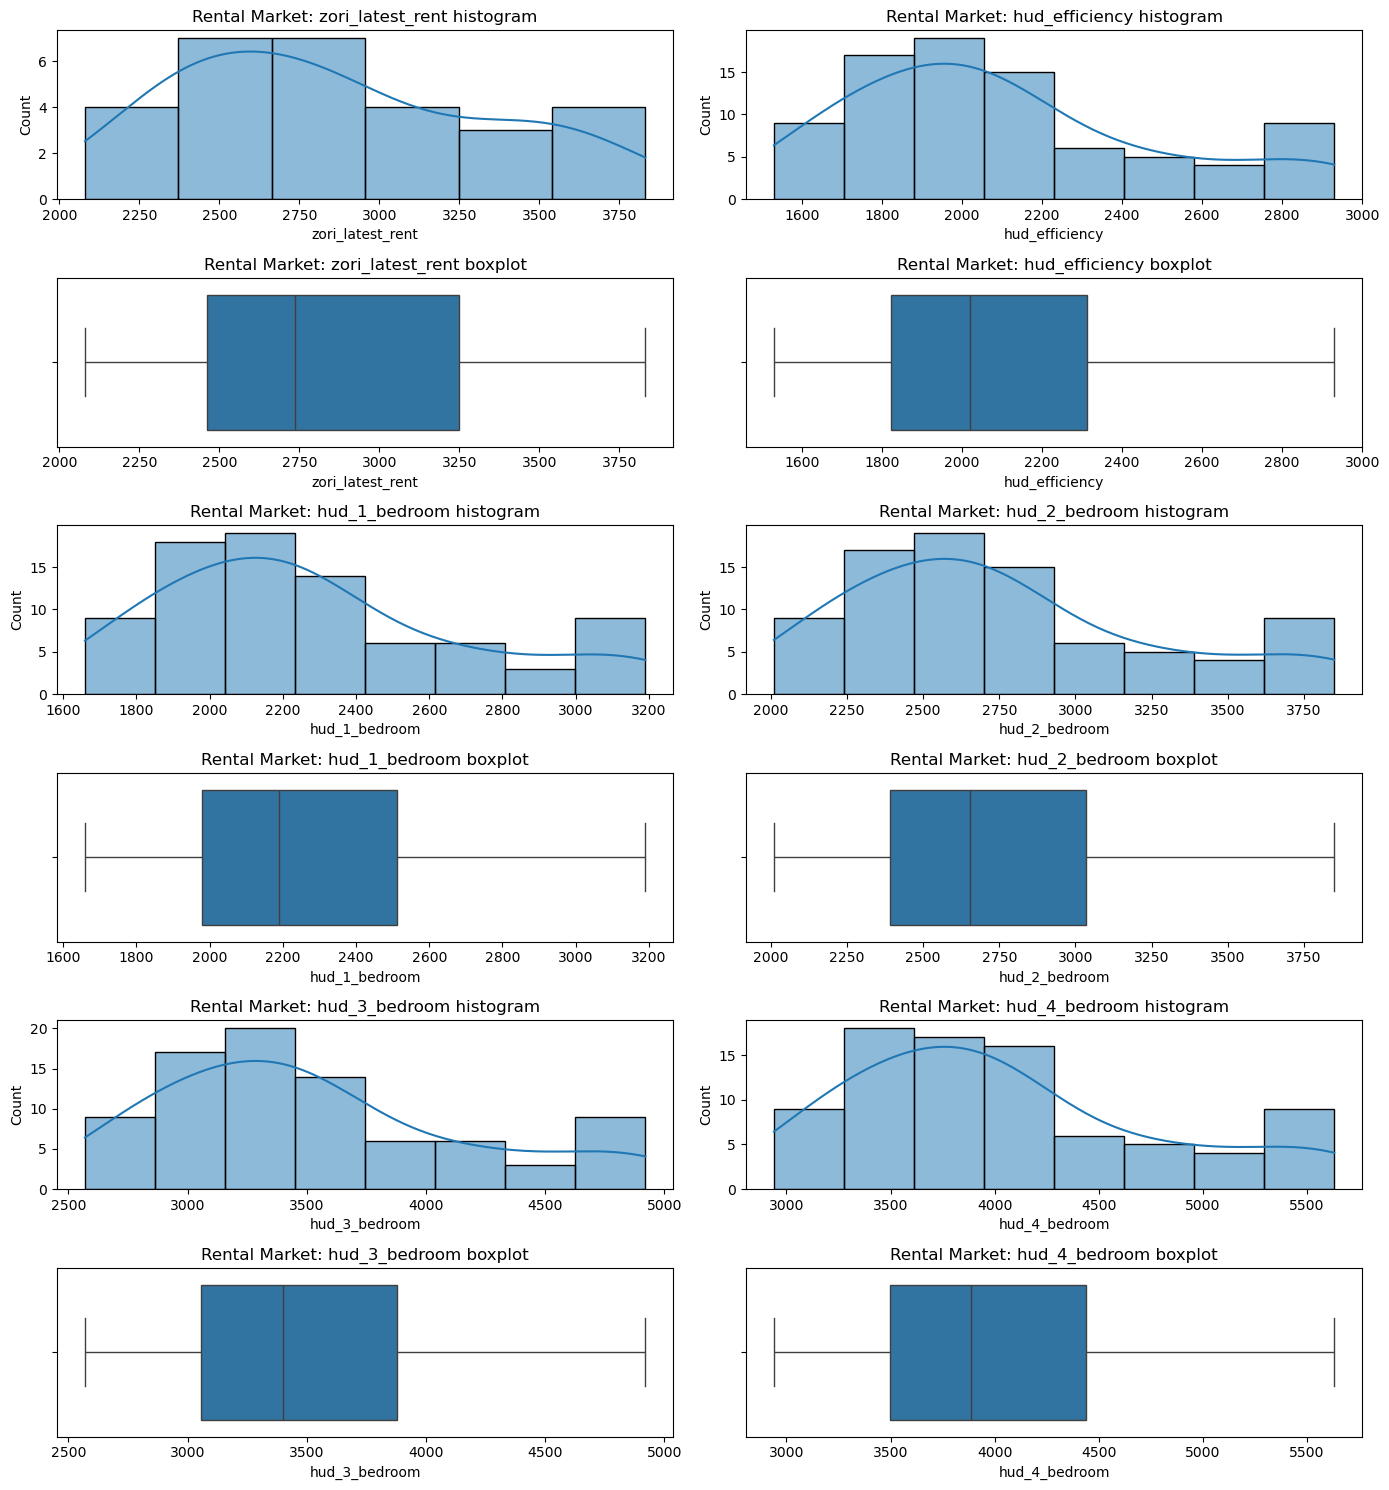


Miami Transit numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
transit_stop_count,78.0,0,0,66,8.905128e+01,54.129690,1.000000e+00,2.510000e+02,0.436088,0
unique_route_count,78.0,0,0,20,8.820513e+00,5.445703,1.000000e+00,2.800000e+01,1.058572,0
bus_route_count,78.0,0,0,21,8.538462e+00,5.031569,1.000000e+00,2.600000e+01,0.894721,0
metrorail_route_count,78.0,0,64,2,1.794872e-01,0.386244,0.000000e+00,1.000000e+00,1.703315,0
metromover_route_count,78.0,0,73,3,1.025641e-01,0.413718,0.000000e+00,2.000000e+00,4.114727,0
weekday_departures,78.0,0,0,78,5.165205e+03,3685.067299,1.500000e+01,1.880200e+04,0.917631,0
saturday_departures,75.0,3,0,75,4.345240e+03,3261.318026,1.500000e+01,1.710000e+04,1.154959,0
sunday_departures,75.0,3,0,74,3.196293e+03,2425.817175,1.400000e+01,1.283700e+04,1.288387,0
weekday_median_headway_minutes,78.0,0,0,46,3.055988e+01,10.724580,9.000000e+00,6.000000e+01,0.713755,0
weekend_median_headway_minutes,75.0,3,0,68,2.494300e+01,18.131652,7.183333e+00,9.723333e+01,2.732612,0


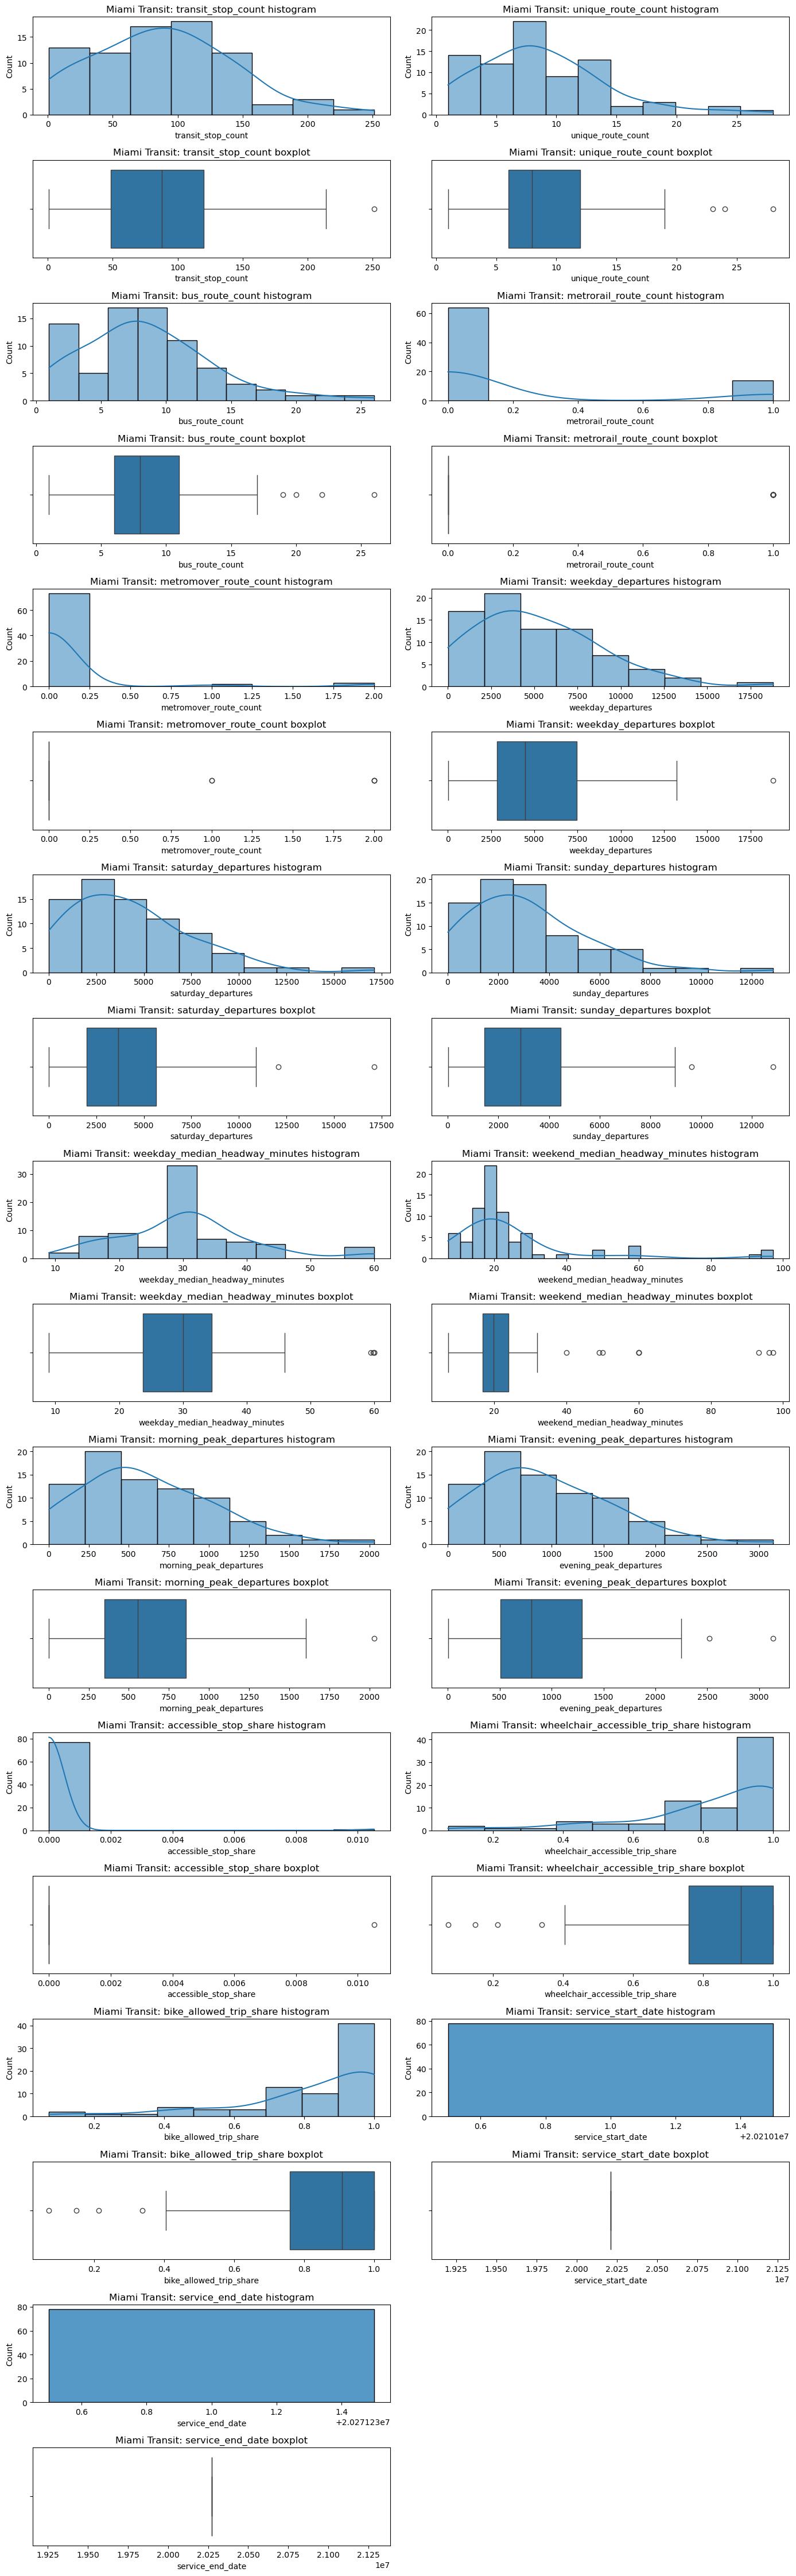


Miami Rents numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
zori_2026_01,28.0,56,0,28,2808.393565,484.297892,2122.036267,3856.182758,0.507841,0
zori_2026_02,28.0,56,0,28,2815.328313,484.831759,2137.609440,3866.957877,0.526775,0
zori_2026_03,29.0,55,0,29,2824.940432,480.865278,2107.030074,3846.303678,0.487892,0
zori_2026_04,29.0,55,0,29,2836.546122,485.128576,2100.077129,3859.062284,0.498077,0
zori_2026_05,29.0,55,0,29,2838.324590,492.249090,2097.444334,3834.779849,0.450974,0
zori_2026_06,29.0,55,0,29,2837.688464,491.790093,2106.902143,3831.772434,0.479971,0
zori_2026_07,29.0,55,0,29,2850.054517,486.158263,2127.589713,3813.449590,0.457596,0
zori_2026_08,29.0,55,0,29,2857.159062,483.033805,2079.871969,3831.361774,0.458446,0
zori_latest_rent,29.0,55,0,29,2857.159062,483.033805,2079.871969,3831.361774,0.458446,0
hud_efficiency,84.0,0,0,61,2102.500000,387.891660,1530.000000,2930.000000,0.713876,0


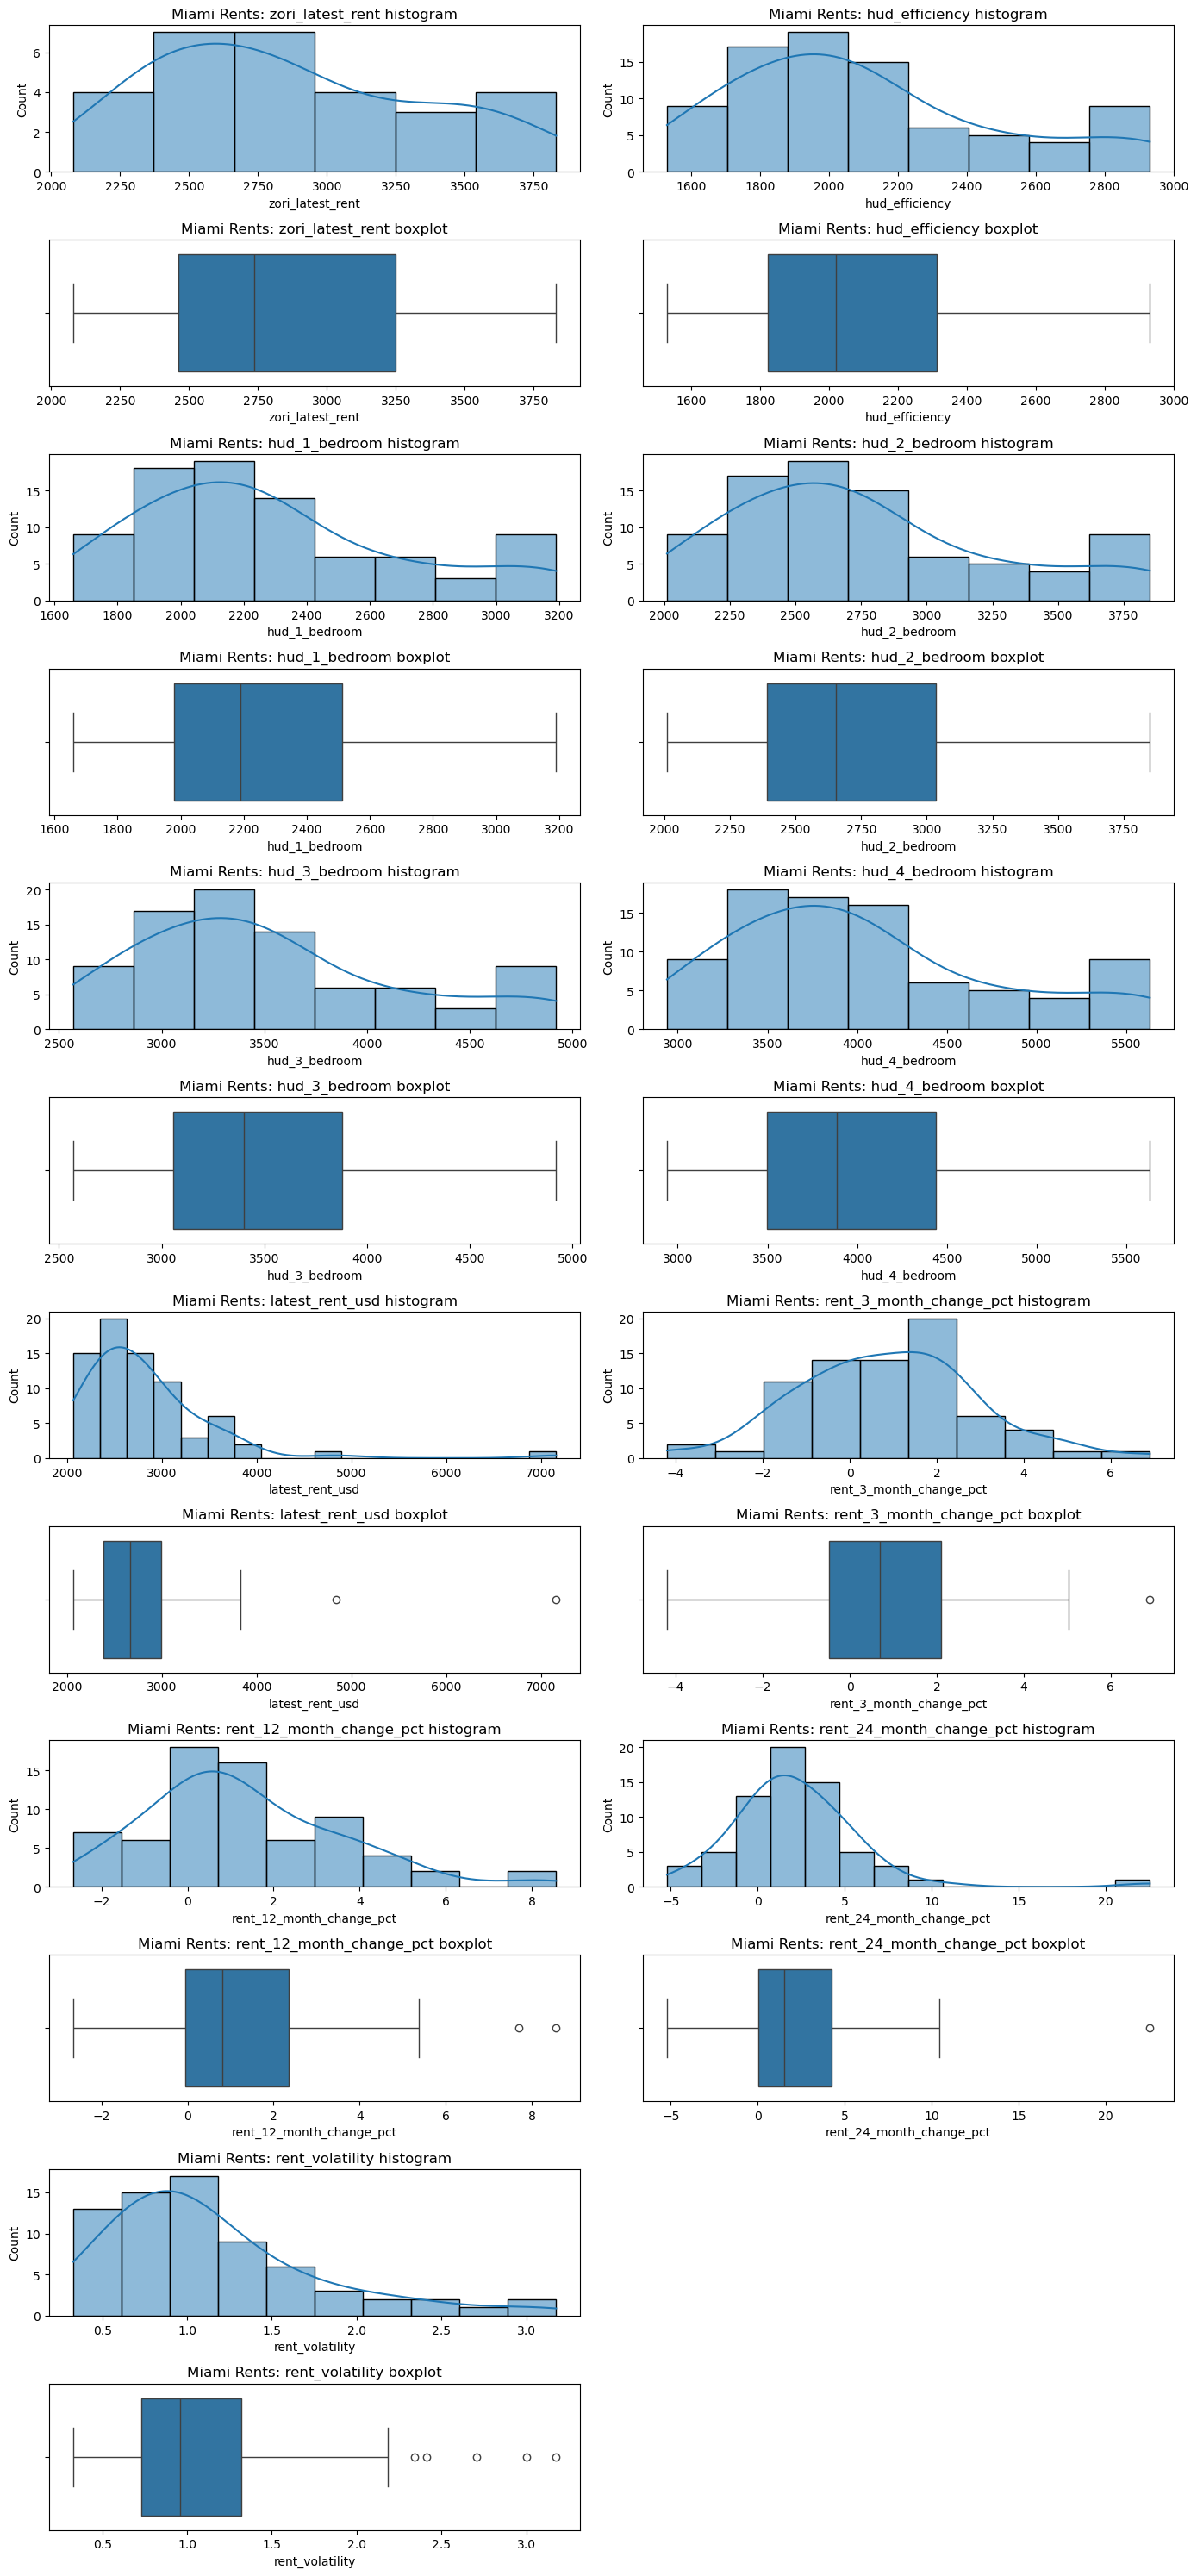


Rent Trends numeric profile


,count,missing_count,zero_count,unique_count,mean,std,min,max,skewness,negative_count
latest_rent_usd,74.0,0,0,74,2817.263804,722.147531,2062.500000,7161.927609,3.414464,0
rent_3_month_change_pct,74.0,0,0,74,0.852271,2.021586,-4.203373,6.899490,0.191988,25
rent_12_month_change_pct,70.0,4,0,70,1.299879,2.257379,-2.650460,8.558722,0.849291,18
rent_24_month_change_pct,66.0,8,0,66,2.186263,3.874457,-5.222038,22.552969,2.230300,15
rent_volatility,70.0,4,0,70,1.139191,0.623766,0.328840,3.176877,1.329227,0


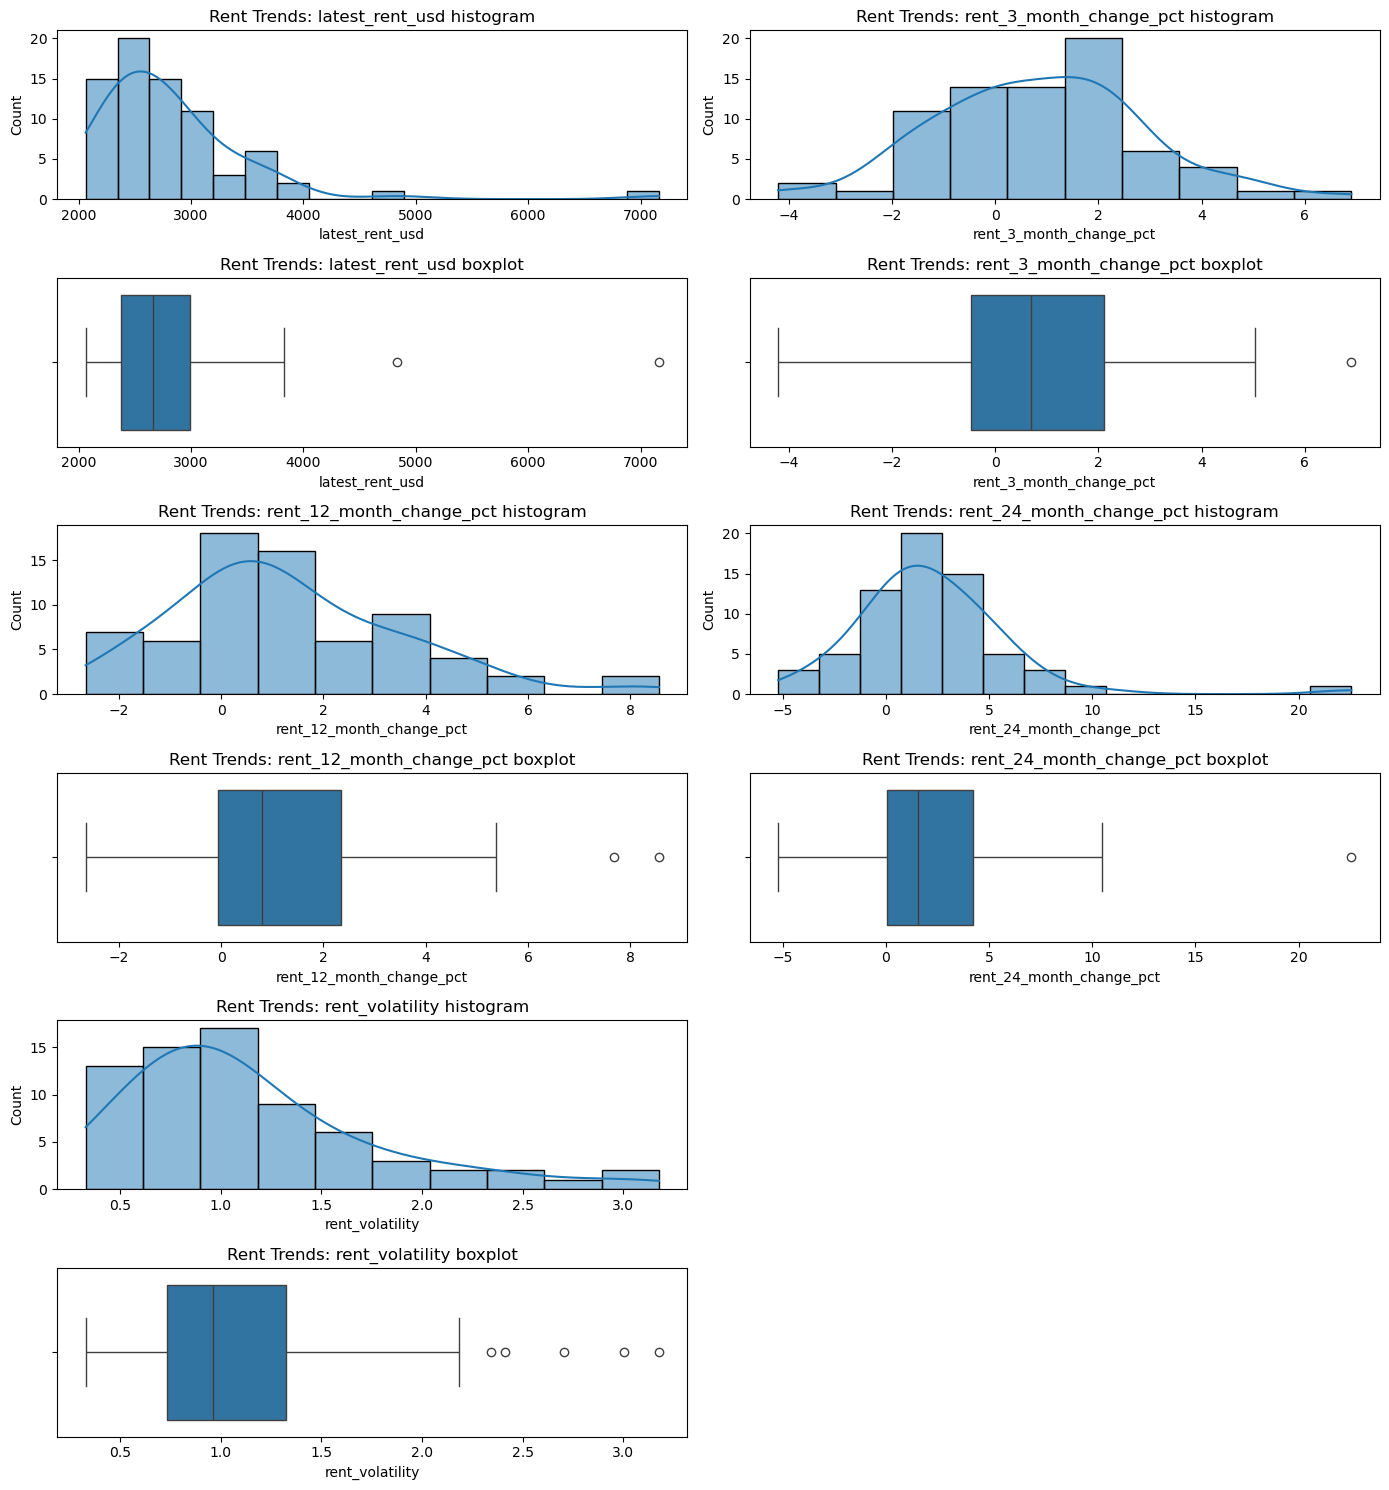

In [9]:
def profile_numeric_columns(frame):
    numeric = frame.select_dtypes(include='number')
    if numeric.empty: return pd.DataFrame()
    profile = numeric.describe().T
    profile['missing_count'], profile['zero_count'] = numeric.isna().sum(), (numeric == 0).sum()
    profile['unique_count'], profile['skewness'] = numeric.nunique(dropna=True), numeric.skew()
    profile['negative_count'] = (numeric < 0).sum()
    return profile[['count', 'missing_count', 'zero_count', 'unique_count', 'mean', 'std', 'min', 'max', 'skewness', 'negative_count']]


def plot_numeric_distributions(frame, dataset_name, excluded_columns):
    numeric_columns = [c for c in frame.select_dtypes(include='number').columns if c not in set(excluded_columns)]
    if not numeric_columns: print(f'No numeric columns to plot for {dataset_name}.'); return
    columns_per_row, rows = 2, math.ceil(len(numeric_columns) / 2)
    figure, axes = plt.subplots(rows * 2, columns_per_row, figsize=(14, rows * 5), squeeze=False)
    for index, column in enumerate(numeric_columns):
        row, column_index = (index // 2) * 2, index % 2
        values = frame[column].dropna()
        sns.histplot(values, kde=values.nunique() > 1, ax=axes[row, column_index])
        axes[row, column_index].set_title(f'{dataset_name}: {column} histogram')
        sns.boxplot(x=values, ax=axes[row + 1, column_index])
        axes[row + 1, column_index].set_title(f'{dataset_name}: {column} boxplot')
    for index in range(len(numeric_columns), rows * 2):
        row, column_index = (index // 2) * 2, index % 2
        axes[row, column_index].set_visible(False); axes[row + 1, column_index].set_visible(False)
    figure.tight_layout(); plt.show()
for dataset_name, frame in cleaned_data.items():
    print(f'\n{dataset_name} numeric profile')
    display(profile_numeric_columns(frame))
    zip_column = DATASETS[dataset_name]['zip_column']
    date_columns = [c for c in frame.columns if c[:4].isdigit() or (c.startswith('zori_') and c[5:9].isdigit())]
    plot_numeric_distributions(frame, dataset_name, [zip_column, *date_columns])

## 3. Categorical value counts and cross-dataset ZIP coverage

Value counts identify unexpected labels. Coverage comparison identifies the ZIPs shared
across all configured datasets and differences in geographic coverage. Miami Rents is a
merge of two sources, so its coverage is not an independent source of evidence.


In [10]:
for dataset_name, frame in cleaned_data.items():
    print(f'\n{dataset_name} categorical value counts')
    for column in frame.select_dtypes(exclude='number').columns:
        print(f'{column}:'); display(frame[column].value_counts(dropna=False).rename('count').to_frame())
zip_sets = {name: set(frame[DATASETS[name]['zip_column']].dropna()) for name, frame in cleaned_data.items()}
shared_zips = set.intersection(*zip_sets.values())
coverage_rows = []
for dataset_name, zip_values in zip_sets.items():
    other_zips = set().union(*(values for name, values in zip_sets.items() if name != dataset_name))
    coverage_rows.append({'dataset': dataset_name, 'zip_count': len(zip_values), 'shared_by_all_datasets': len(shared_zips), 'only_in_this_dataset': len(zip_values - other_zips)})
display(pd.DataFrame(coverage_rows))
print(f'ZIPs shared by all {len(DATASETS)} datasets: {len(shared_zips)}')
display(pd.DataFrame({'shared_zip_code': sorted(shared_zips)}))


Miami Home Values categorical value counts
RegionName:


,count
RegionName,
33177,1
33125,1
33176,1
33165,1
33193,1
33175,1
33126,1
33155,1
33135,1


RegionType:


,count
RegionType,
zip,30


StateName:


,count
StateName,
FL,30


... (55 outputs left out)

,count
source_date,
2026-08,74


,dataset,zip_count,shared_by_all_datasets,only_in_this_dataset
0,Miami Home Values,30,29,0
1,Miami Rental Values,29,29,0
2,Rental Market,84,29,0
3,Miami Transit,78,29,0
4,Miami Rents,84,29,0
5,Rent Trends,74,29,0


ZIPs shared by all 6 datasets: 29


,shared_zip_code
0,33122
1,33125
2,33126
3,33127
4,33128
5,33129
6,33130
7,33131
8,33132
9,33133


## 4. Final data-quality checks

These checks confirm that filtered frames contain only Miami-Dade ZCTAs, ZIP codes remain strings, columns are unique, and no configured sentinel values remain.

In [11]:
quality_rows = []
for dataset_name, config in DATASETS.items():
    frame, zip_column = cleaned_data[dataset_name], config['zip_column']
    quality_rows.append({'dataset': dataset_name, 'rows': len(frame), 'zip_dtype': str(frame[zip_column].dtype), 'invalid_zip_rows': int((~frame[zip_column].isin(allowed_zips)).sum()), 'duplicate_rows': int(frame.duplicated().sum()), 'duplicate_columns': int(frame.columns.duplicated().sum()), 'sentinel_values_remaining': int(frame.isin([-666666666, -6666666666]).sum().sum())})
quality_checks = pd.DataFrame(quality_rows)
display(quality_checks)
assert (quality_checks['invalid_zip_rows'] == 0).all()
assert (quality_checks['duplicate_columns'] == 0).all()
assert (quality_checks['sentinel_values_remaining'] == 0).all()
print('All final data-quality checks passed.')

,dataset,rows,zip_dtype,invalid_zip_rows,duplicate_rows,duplicate_columns,sentinel_values_remaining
0,Miami Home Values,30,string,0,0,0,0
1,Miami Rental Values,29,string,0,0,0,0
2,Rental Market,84,string,0,0,0,0
3,Miami Transit,78,string,0,0,0,0
4,Miami Rents,84,string,0,0,0,0
5,Rent Trends,74,string,0,0,0,0


All final data-quality checks passed.


## 5. Merged rents: coverage, missingness, and merge integrity

`miami-rents.csv` combines Rental Market and Rent Trends using `zip_code`. Validate that
every source ZIP and value survived the merge, then inspect availability for each new
column. Blank fields mean unavailable observations, not zero rent or zero growth.
The data still contains one row per ZIP; ZIP codes remain identifiers.


Merge verified: 84 unique ZIPs; 25 columns; all source values preserved.


,available_zip_count,missing_zip_count,missing_percent
zip_code,84,0,0.0
zori_2026_01,28,56,66.7
zori_2026_02,28,56,66.7
zori_2026_03,29,55,65.5
zori_2026_04,29,55,65.5
zori_2026_05,29,55,65.5
zori_2026_06,29,55,65.5
zori_2026_07,29,55,65.5
zori_2026_08,29,55,65.5
zori_latest_rent,29,55,65.5


,has_hud,has_market_zori,has_trend_rent,zip_count
0,True,False,False,10
1,True,False,True,45
2,True,True,True,29


ZIPs without rent-trend observations:


,zip_code,hud_2_bedroom
8,33031,2510
13,33039,2560
17,33090,2560
18,33101,2560
19,33109,3690
20,33114,2560
21,33116,2560
23,33124,2560
53,33158,3290
78,33187,3050


Trend observation dates (including missing):


,zip_count
source_date,
2026-08,74
Missing,10


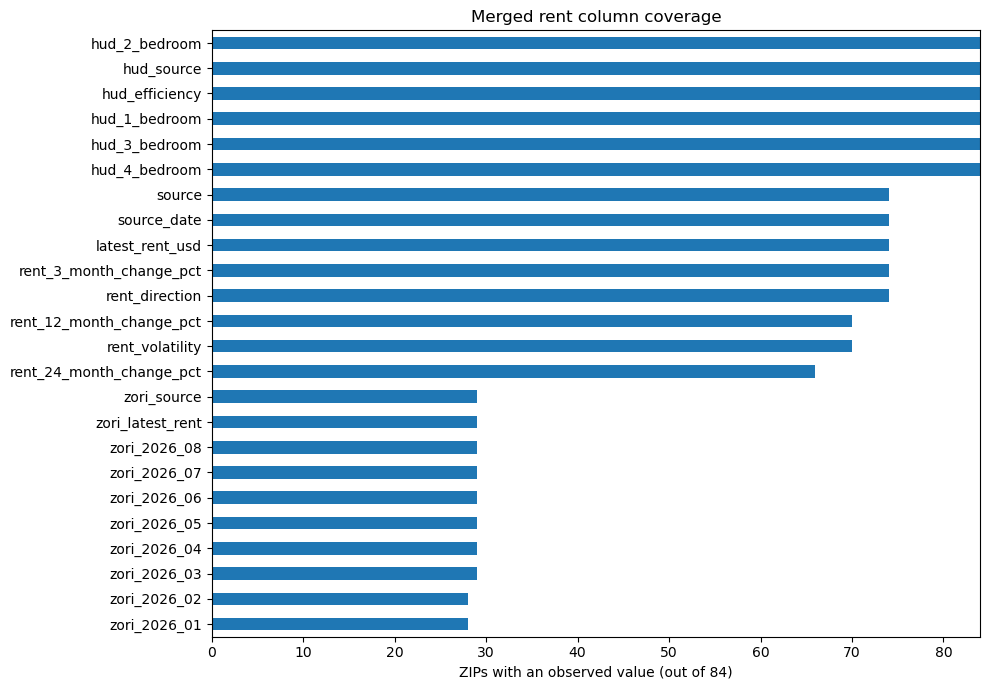

In [12]:
rents = cleaned_data['Miami Rents'].copy().sort_values('zip_code').reset_index(drop=True)
market = cleaned_data['Rental Market'].set_index('zip_code').sort_index()
trends = cleaned_data['Rent Trends'].set_index('zip_code').sort_index()
merged = rents.set_index('zip_code').sort_index()
assert rents['zip_code'].str.fullmatch(r'\d{5}').all()
assert rents['zip_code'].is_unique
assert set(merged.index) == set(market.index) | set(trends.index)
assert len(rents.columns) == len(set(market.columns) | set(trends.columns)) + 1
for original in (market, trends):
    for column in original.columns:
        pd.testing.assert_series_equal(
            merged.loc[original.index, column], original[column],
            check_dtype=False, check_exact=True,
        )
print(f'Merge verified: {len(rents)} unique ZIPs; {len(rents.columns)} columns; all source values preserved.')

rent_missingness = pd.DataFrame({
    'available_zip_count': rents.notna().sum(),
    'missing_zip_count': rents.isna().sum(),
    'missing_percent': rents.isna().mean().mul(100).round(1),
})
display(rent_missingness)
coverage_flags = rents.assign(
    has_hud=rents['hud_2_bedroom'].notna(),
    has_market_zori=rents['zori_latest_rent'].notna(),
    has_trend_rent=rents['latest_rent_usd'].notna(),
)
display(coverage_flags.groupby(
    ['has_hud', 'has_market_zori', 'has_trend_rent'], dropna=False,
).size().rename('zip_count').reset_index())
print('ZIPs without rent-trend observations:')
display(rents.loc[rents['latest_rent_usd'].isna(), ['zip_code', 'hud_2_bedroom']])
print('Trend observation dates (including missing):')
display(rents['source_date'].fillna('Missing').value_counts().rename('zip_count').to_frame())

fig, ax = plt.subplots(figsize=(10, 7))
rent_missingness.drop(index='zip_code')['available_zip_count'].sort_values().plot.barh(ax=ax)
ax.set(xlabel=f'ZIPs with an observed value (out of {len(rents)})', title='Merged rent column coverage')
ax.set_xlim(0, len(rents))
fig.tight_layout()
plt.show()


## 6. Rent levels, duplicate measures, and benchmark checks

Compare `latest_rent_usd` with `zori_latest_rent` only where both exist. Compare the market
latest field with the last monthly ZORI column as a separate consistency check. HUD
figures are bedroom-specific benchmarks; ZORI is a market rent index. Their relationship
is descriptive and does not establish affordability or a like-for-like price gap.


,count,mean,std,min,25%,50%,75%,max
latest_rent_usd,74.0,2817.26,722.15,2062.50,2376.62,2661.65,2986.3,7161.93
zori_latest_rent,29.0,2857.16,483.03,2079.87,2459.89,2735.66,3247.5,3831.36
hud_efficiency,84.0,2102.50,387.89,1530.00,1822.50,2020.00,2312.5,2930.00
hud_1_bedroom,84.0,2284.76,422.15,1660.00,1980.00,2190.00,2512.5,3190.00
hud_2_bedroom,84.0,2761.67,510.35,2010.00,2390.00,2655.00,3035.0,3850.00
hud_3_bedroom,84.0,3530.12,652.45,2570.00,3057.50,3400.00,3877.5,4920.00
hud_4_bedroom,84.0,4038.81,747.39,2940.00,3495.00,3885.00,4437.5,5630.00


Latest-rent overlap: 29 ZIPs; differences above $0.01: 0


,zip_code,latest_rent_usd,zori_latest_rent,difference_usd


Market latest vs. zori_2026_08: 29 comparable ZIPs; 0 differences above $0.01.
Nonpositive rent observations:


,nonpositive_observations
latest_rent_usd,0
zori_latest_rent,0
hud_efficiency,0
hud_1_bedroom,0
hud_2_bedroom,0
hud_3_bedroom,0
hud_4_bedroom,0
zori_2026_01,0
zori_2026_02,0
zori_2026_03,0


HUD bedroom-order checks: 84 complete ZIPs; 0 decreasing benchmark sequences.


,zip_code,hud_efficiency,hud_1_bedroom,hud_2_bedroom,hud_3_bedroom,hud_4_bedroom


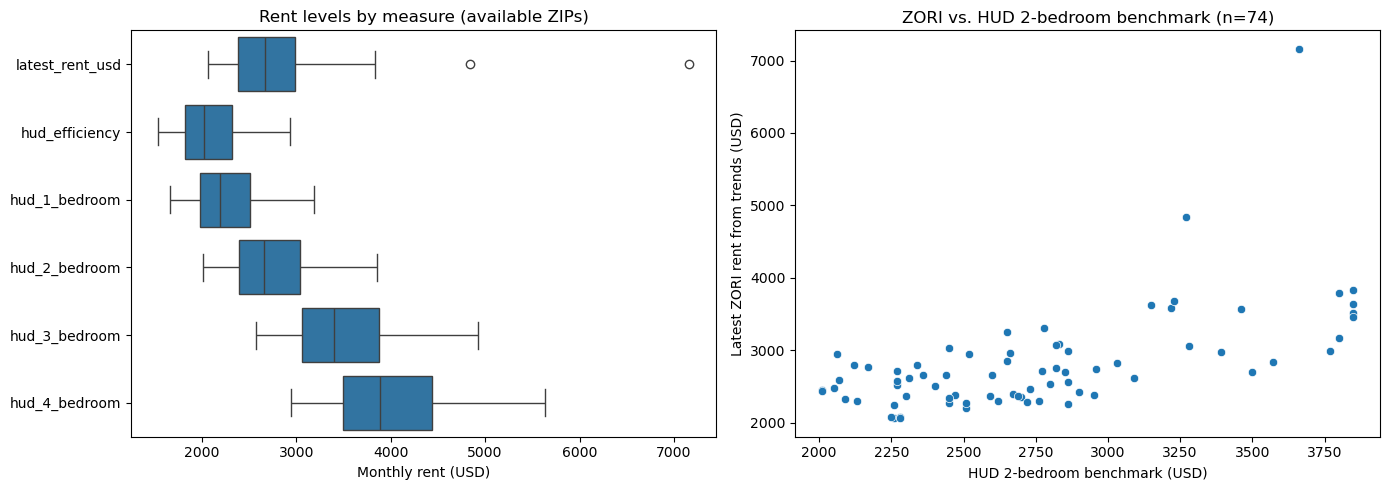

In [13]:
zori_months = sorted(column for column in rents if pd.Series([column]).str.fullmatch(r'zori_\d{4}_\d{2}').iloc[0])
hud_columns = ['hud_efficiency', 'hud_1_bedroom', 'hud_2_bedroom', 'hud_3_bedroom', 'hud_4_bedroom']
level_columns = ['latest_rent_usd', 'zori_latest_rent', *hud_columns]
display(rents[level_columns].describe().T.round(2))

latest_comparison = rents.dropna(subset=['latest_rent_usd', 'zori_latest_rent']).copy()
latest_comparison['difference_usd'] = latest_comparison['latest_rent_usd'] - latest_comparison['zori_latest_rent']
latest_disagreements = latest_comparison.loc[
    ~np.isclose(latest_comparison['latest_rent_usd'], latest_comparison['zori_latest_rent'], rtol=0, atol=0.01),
    ['zip_code', 'latest_rent_usd', 'zori_latest_rent', 'difference_usd'],
]
print(f'Latest-rent overlap: {len(latest_comparison)} ZIPs; differences above $0.01: {len(latest_disagreements)}')
display(latest_disagreements)
last_month = zori_months[-1]
month_pair = rents.dropna(subset=['zori_latest_rent', last_month])
month_mismatch_count = int((~np.isclose(month_pair['zori_latest_rent'], month_pair[last_month], rtol=0, atol=0.01)).sum())
print(f'Market latest vs. {last_month}: {len(month_pair)} comparable ZIPs; {month_mismatch_count} differences above $0.01.')

nonpositive_rents = rents[level_columns + zori_months].le(0).sum().rename('nonpositive_observations')
print('Nonpositive rent observations:')
display(nonpositive_rents.to_frame())
hud_complete = rents[hud_columns].notna().all(axis=1)
hud_order_issues = hud_complete & rents[hud_columns].diff(axis=1).iloc[:, 1:].lt(0).any(axis=1)
print(f'HUD bedroom-order checks: {int(hud_complete.sum())} complete ZIPs; {int(hud_order_issues.sum())} decreasing benchmark sequences.')
display(rents.loc[hud_order_issues, ['zip_code', *hud_columns]])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
level_long = rents[['latest_rent_usd', *hud_columns]].melt(var_name='measure', value_name='monthly_rent_usd').dropna()
sns.boxplot(data=level_long, x='monthly_rent_usd', y='measure', ax=axes[0])
axes[0].set(title='Rent levels by measure (available ZIPs)', xlabel='Monthly rent (USD)', ylabel='')
benchmark_pair = rents.dropna(subset=['latest_rent_usd', 'hud_2_bedroom'])
sns.scatterplot(data=benchmark_pair, x='hud_2_bedroom', y='latest_rent_usd', ax=axes[1])
axes[1].set(title=f'ZORI vs. HUD 2-bedroom benchmark (n={len(benchmark_pair)})', xlabel='HUD 2-bedroom benchmark (USD)', ylabel='Latest ZORI rent from trends (USD)')
fig.tight_layout()
plt.show()


## 7. Growth, direction, volatility, and unusual values

Growth fields report percentage change across 3, 12, and 24 months. `rent_volatility`
measures the standard deviation of monthly percentage changes over 12 months (percentage
points). Check direction labels against the generating script's 3-month thresholds:
above +1% is increasing, below −1% is decreasing, otherwise stable. Each statistic uses
its own available observations. IQR flags identify values for review and do not remove rows.


,count,mean,std,min,25%,50%,75%,max
rent_3_month_change_pct,74.0,0.852,2.022,-4.203,-0.473,0.699,2.102,6.899
rent_12_month_change_pct,70.0,1.300,2.257,-2.650,-0.057,0.807,2.347,8.559
rent_24_month_change_pct,66.0,2.186,3.874,-5.222,0.055,1.544,4.237,22.553
rent_volatility,70.0,1.139,0.624,0.329,0.731,0.960,1.322,3.177


,zip_count,percent_of_all_zips
rent_direction,,
increasing,36,42.9
stable,25,29.8
decreasing,13,15.5
Missing,10,11.9


Direction-label mismatches: 0
Negative volatility observations: 0


,zip_code,rent_3_month_change_pct,rent_direction


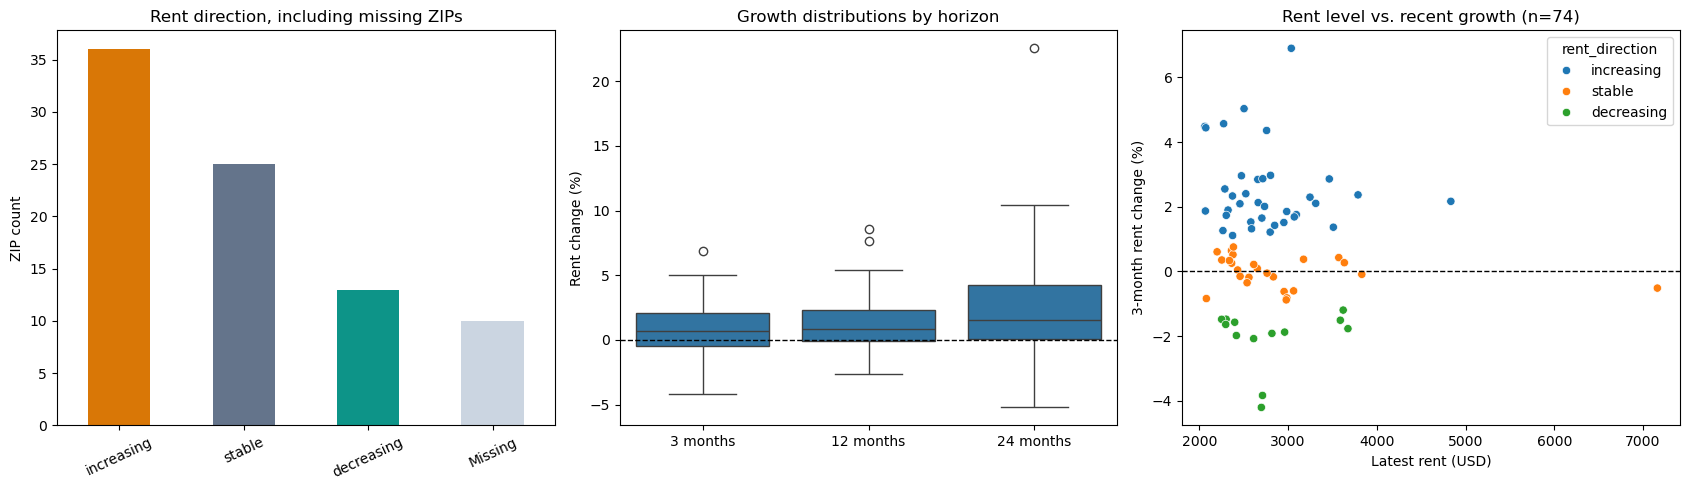

IQR review flags: 11 observations across 9 ZIPs; no rows removed.


,zip_code,column,value,lower_fence,upper_fence
0,33149,latest_rent_usd,7161.928,1462.101,3900.824
1,33154,latest_rent_usd,4834.762,1462.101,3900.824
2,33055,rent_3_month_change_pct,6.899,-4.336,5.965
3,33056,rent_12_month_change_pct,7.686,-3.664,5.953
4,33185,rent_12_month_change_pct,8.559,-3.664,5.953
5,33055,rent_24_month_change_pct,22.553,-6.218,10.510
6,33013,rent_volatility,2.342,-0.155,2.209
7,33055,rent_volatility,3.002,-0.155,2.209
8,33144,rent_volatility,2.413,-0.155,2.209
9,33147,rent_volatility,2.705,-0.155,2.209


In [14]:
growth_columns = ['rent_3_month_change_pct', 'rent_12_month_change_pct', 'rent_24_month_change_pct']
trend_columns = [*growth_columns, 'rent_volatility']
display(rents[trend_columns].describe().T.round(3))
direction_order = ['increasing', 'stable', 'decreasing', 'Missing']
direction_counts = rents['rent_direction'].fillna('Missing').value_counts().reindex(direction_order, fill_value=0)
display(pd.DataFrame({
    'zip_count': direction_counts,
    'percent_of_all_zips': direction_counts.div(len(rents)).mul(100).round(1),
}))
expected_direction = pd.Series(pd.NA, index=rents.index, dtype='string')
known_growth = rents['rent_3_month_change_pct'].notna()
expected_direction.loc[known_growth] = np.select(
    [rents.loc[known_growth, 'rent_3_month_change_pct'].gt(1),
     rents.loc[known_growth, 'rent_3_month_change_pct'].lt(-1)],
    ['increasing', 'decreasing'], default='stable',
)
direction_issues = rents['rent_direction'].astype('string').fillna('Missing').ne(expected_direction.fillna('Missing'))
print(f'Direction-label mismatches: {int(direction_issues.sum())}')
print(f'Negative volatility observations: {int(rents["rent_volatility"].lt(0).sum())}')
display(rents.loc[direction_issues, ['zip_code', 'rent_3_month_change_pct', 'rent_direction']])

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
direction_counts.plot.bar(ax=axes[0], color=['#d97706', '#64748b', '#0d9488', '#cbd5e1'], rot=25)
axes[0].set(title='Rent direction, including missing ZIPs', ylabel='ZIP count', xlabel='')
growth_long = rents[growth_columns].rename(columns=dict(zip(growth_columns, ['3 months', '12 months', '24 months']))).melt(var_name='period', value_name='change_pct').dropna()
sns.boxplot(data=growth_long, x='period', y='change_pct', ax=axes[1])
axes[1].axhline(0, color='black', linewidth=1, linestyle='--')
axes[1].set(title='Growth distributions by horizon', xlabel='', ylabel='Rent change (%)')
scatter_rows = rents.dropna(subset=['latest_rent_usd', 'rent_3_month_change_pct', 'rent_direction'])
sns.scatterplot(data=scatter_rows, x='latest_rent_usd', y='rent_3_month_change_pct', hue='rent_direction', ax=axes[2])
axes[2].axhline(0, color='black', linewidth=1, linestyle='--')
axes[2].set(title=f'Rent level vs. recent growth (n={len(scatter_rows)})', xlabel='Latest rent (USD)', ylabel='3-month rent change (%)')
fig.tight_layout()
plt.show()

outlier_rows = []
for column in ['latest_rent_usd', *trend_columns]:
    observed = rents[column].dropna()
    q1, q3 = observed.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = rents.loc[rents[column].lt(lower) | rents[column].gt(upper), ['zip_code', column]]
    for _, row in flagged.iterrows():
        outlier_rows.append({'zip_code': row['zip_code'], 'column': column, 'value': row[column], 'lower_fence': lower, 'upper_fence': upper})
outlier_review = pd.DataFrame(outlier_rows, columns=['zip_code', 'column', 'value', 'lower_fence', 'upper_fence'])
print(f'IQR review flags: {len(outlier_review)} observations across {outlier_review["zip_code"].nunique()} ZIPs; no rows removed.')
display(outlier_review.round(3))


## 8. Monthly rent paths and correlations

Plot January–August ZORI coverage by month. Use only ZIPs observed in **every** month for
the median and interquartile band so changing coverage does not change the comparison
cohort. This is an unweighted summary of ZIP estimates, not an official Miami rent index.

Correlations use pairwise complete observations with at least 3 ZIPs per pair. Show the
sample size alongside each coefficient. Exclude the duplicate latest-rent field and
monthly ZORI columns to reduce repeated measures. These exploratory associations do not
show causation; HUD bedroom benchmarks are also strongly related by construction.


,month,available_zips,balanced_cohort_zips,balanced_median_usd,balanced_q25_usd,balanced_q75_usd
0,2026-01-01,28,28,2684.58,2428.76,3291.77
1,2026-02-01,28,28,2677.50,2431.36,3277.22
2,2026-03-01,29,28,2713.10,2427.27,3249.55
3,2026-04-01,29,28,2725.15,2438.38,3206.37
4,2026-05-01,29,28,2723.47,2380.25,3191.94
5,2026-06-01,29,28,2729.48,2376.22,3201.46
6,2026-07-01,29,28,2745.47,2400.11,3290.40
7,2026-08-01,29,28,2767.25,2439.88,3263.69


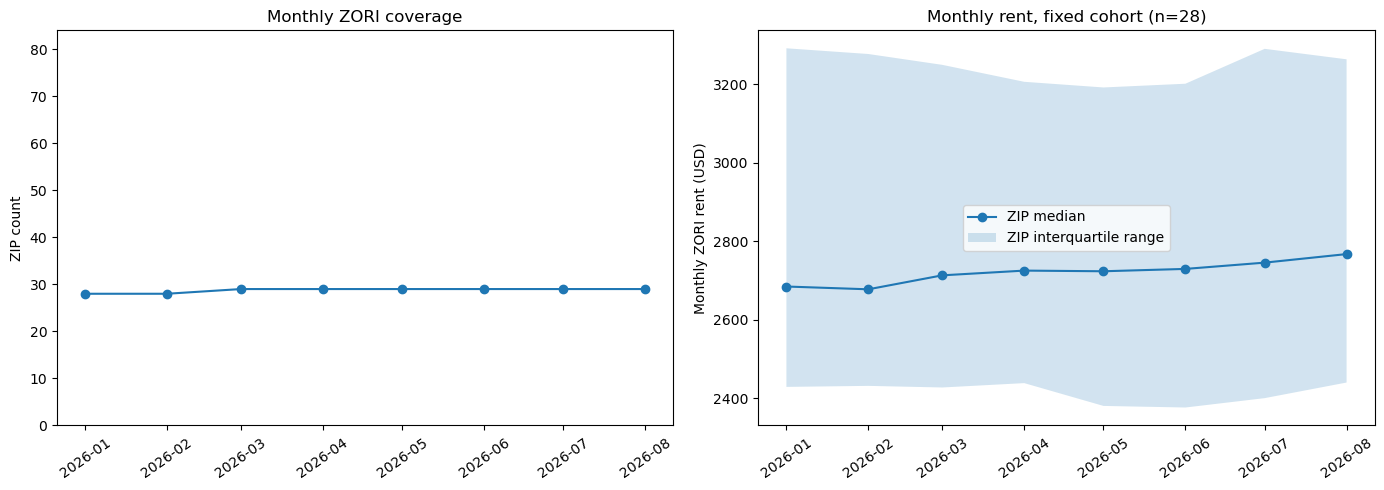

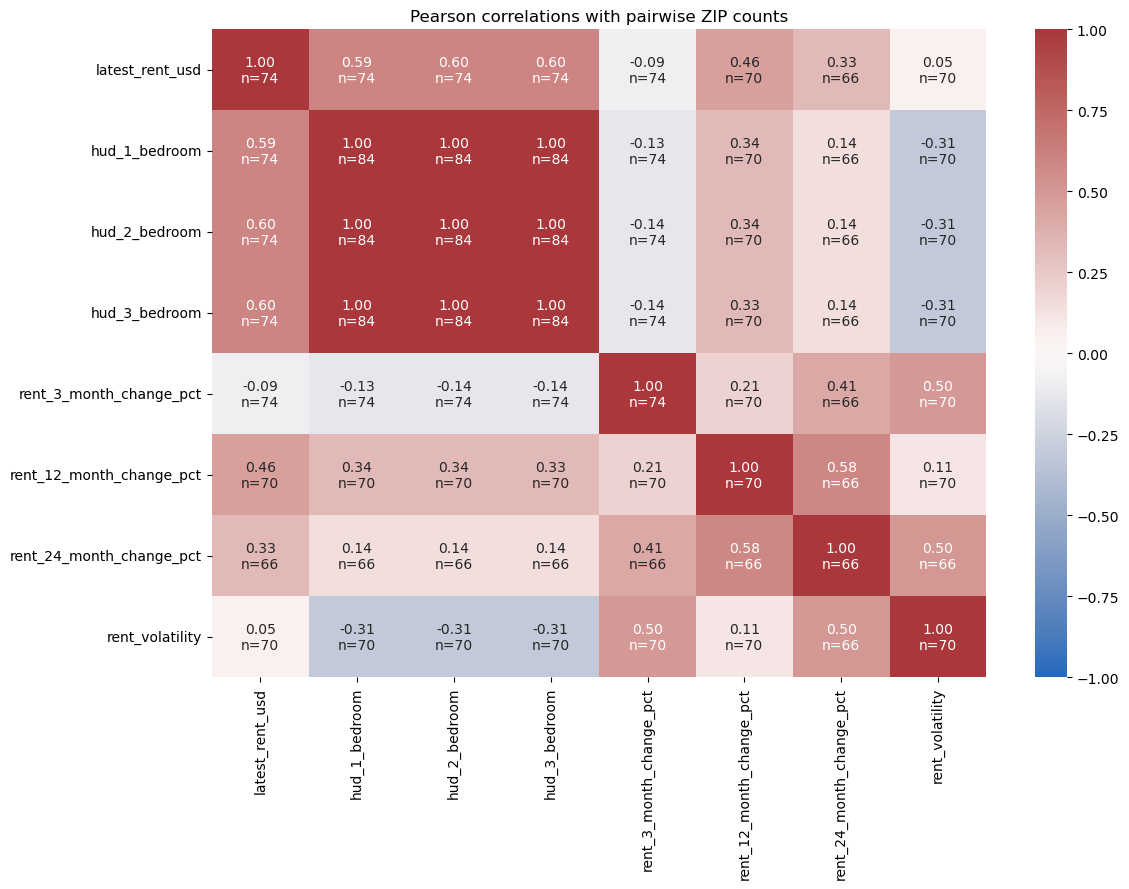

In [15]:
month_dates = pd.to_datetime([column.removeprefix('zori_').replace('_', '-') for column in zori_months])
monthly_coverage = rents[zori_months].notna().sum()
balanced_monthly = rents.dropna(subset=zori_months)[zori_months]
monthly_summary = pd.DataFrame({
    'month': month_dates,
    'available_zips': monthly_coverage.to_numpy(),
    'balanced_cohort_zips': len(balanced_monthly),
    'balanced_median_usd': balanced_monthly.median().to_numpy(),
    'balanced_q25_usd': balanced_monthly.quantile(0.25).to_numpy(),
    'balanced_q75_usd': balanced_monthly.quantile(0.75).to_numpy(),
})
display(monthly_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(month_dates, monthly_coverage.to_numpy(), marker='o')
axes[0].set(title='Monthly ZORI coverage', ylabel='ZIP count', ylim=(0, len(rents)))
if len(balanced_monthly):
    axes[1].plot(month_dates, monthly_summary['balanced_median_usd'], marker='o', label='ZIP median')
    axes[1].fill_between(month_dates, monthly_summary['balanced_q25_usd'], monthly_summary['balanced_q75_usd'], alpha=0.2, label='ZIP interquartile range')
    axes[1].legend()
axes[1].set(title=f'Monthly rent, fixed cohort (n={len(balanced_monthly)})', ylabel='Monthly ZORI rent (USD)')
for ax in axes:
    ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
plt.show()

correlation_columns = ['latest_rent_usd', 'hud_1_bedroom', 'hud_2_bedroom', 'hud_3_bedroom', *trend_columns]
correlation_data = rents[correlation_columns]
correlations = correlation_data.corr(min_periods=3)
observed_flags = correlation_data.notna().astype(int)
pair_counts = observed_flags.T.dot(observed_flags)
annotations = correlations.copy().astype(object)
for row in correlations.index:
    for column in correlations.columns:
        value = correlations.loc[row, column]
        annotations.loc[row, column] = f'{value:.2f}\nn={pair_counts.loc[row, column]}' if pd.notna(value) else ''
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(correlations, mask=correlations.isna(), annot=annotations, fmt='', cmap='vlag', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Pearson correlations with pairwise ZIP counts')
fig.tight_layout()
plt.show()


## 9. Findings and implications for cleaning

The summary below is calculated from the current CSV. Preserve missing observations,
review flagged values against their sources, and avoid feeding duplicate rent measures
into a model without an explicit feature choice. Benchmark comparisons need compatible
periods and housing definitions; the merged file records trend dates but does not record
a HUD benchmark year. No affordability conclusion follows from these columns alone.


In [16]:
latest_values = rents['latest_rent_usd'].dropna()
latest_count = int(rents['latest_rent_usd'].notna().sum())
market_count = int(rents['zori_latest_rent'].notna().sum())
dates_observed = ', '.join(sorted(rents['source_date'].dropna().unique()))
findings = [
    f'**Coverage:** {len(rents)} unique ZIPs; HUD 2-bedroom benchmarks for {int(rents["hud_2_bedroom"].notna().sum())}; trend rents for {latest_count}; market latest ZORI for {market_count}.',
    f'**Latest trend rents:** median ${latest_values.median():,.2f}, ranging from ${latest_values.min():,.2f} to ${latest_values.max():,.2f} across observed ZIPs. Trend observation month(s): {dates_observed}.',
    f'**Direction:** {direction_counts["increasing"]} increasing, {direction_counts["stable"]} stable, {direction_counts["decreasing"]} decreasing, and {direction_counts["Missing"]} missing.',
    f'**Longer history:** {int(rents["rent_12_month_change_pct"].notna().sum())} ZIPs have 12-month growth; {int(rents["rent_24_month_change_pct"].notna().sum())} have 24-month growth; {int(rents["rent_volatility"].notna().sum())} have volatility.',
    f'**Latest-field consistency:** {len(latest_comparison)} overlapping ZIPs; {len(latest_disagreements)} differences above $0.01. Market latest vs. last monthly observation has {month_mismatch_count} differences above $0.01.',
    f'**Quality review:** {int(nonpositive_rents.sum())} nonpositive rent values, {int(hud_order_issues.sum())} HUD ordering issues, {int(direction_issues.sum())} direction-label mismatches, and {len(outlier_review)} IQR flags. Flags are retained for review.',
    f'**Monthly cohort:** {len(balanced_monthly)} ZIPs have all {len(zori_months)} monthly observations. Monthly plots cover this smaller cohort, not all ZIPs with trend data.',
    '**Cleaning choice:** keep unavailable data missing; preserve both latest-rent fields and their provenance in this EDA; choose features deliberately before downstream modeling.',
]
display(Markdown('\n\n'.join(f'- {finding}' for finding in findings)))


- **Coverage:** 84 unique ZIPs; HUD 2-bedroom benchmarks for 84; trend rents for 74; market latest ZORI for 29.

- **Latest trend rents:** median $2,661.65, ranging from $2,062.50 to $7,161.93 across observed ZIPs. Trend observation month(s): 2026-08.

- **Direction:** 36 increasing, 25 stable, 13 decreasing, and 10 missing.

- **Longer history:** 70 ZIPs have 12-month growth; 66 have 24-month growth; 70 have volatility.

- **Latest-field consistency:** 29 overlapping ZIPs; 0 differences above $0.01. Market latest vs. last monthly observation has 0 differences above $0.01.

- **Quality review:** 0 nonpositive rent values, 0 HUD ordering issues, 0 direction-label mismatches, and 11 IQR flags. Flags are retained for review.

- **Monthly cohort:** 28 ZIPs have all 8 monthly observations. Monthly plots cover this smaller cohort, not all ZIPs with trend data.

- **Cleaning choice:** keep unavailable data missing; preserve both latest-rent fields and their provenance in this EDA; choose features deliberately before downstream modeling.